# Employee Attrition — Exploratory & Statistical Analysis

## Objective

This notebook investigates patterns and statistical associations related to employee attrition.

The analysis focuses on:

- Overall attrition levels
- Attrition patterns across departments and salary groups
- Differences in employee satisfaction, workload, projects, evaluation, and tenure
- Non-linear attrition patterns across workload, project count, and tenure
- Statistical tests of association between employee characteristics and attrition
- Effect-size analysis to distinguish statistical significance from practical association

## Business Questions

1. What proportion of employees left the company?
2. Which employee characteristics are associated with attrition?
3. Which employee groups show elevated observed attrition rates?
4. Which variables show the strongest statistical associations with attrition?
5. What patterns should be considered when developing an employee attrition prediction model?

> **Important:** This analysis identifies associations and observed patterns in historical data. It does not establish that any individual factor caused an employee to leave.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import chi2_contingency, mannwhitneyu

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "project_dataset_combined.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset loaded successfully: 14,999 rows × 11 columns


In [2]:
df_analysis = df.copy()

df_analysis["dept"] = df_analysis["dept"].str.strip()
df_analysis["salary"] = df_analysis["salary"].str.strip().str.lower()
df_analysis["Attrition"] = df_analysis["Attrition"].str.strip().str.lower()

df_analysis["attrition_flag"] = df_analysis["Attrition"].map({
    "yes": 1,
    "no": 0
})

print("Analysis-ready dataset created.")
print(f"Target values: {df_analysis['Attrition'].value_counts().to_dict()}")

Analysis-ready dataset created.
Target values: {'no': 11428, 'yes': 3571}


## 1. Overall Attrition

The first step is to establish the overall proportion of employees who left the company.

This provides the baseline against which differences across employee characteristics and groups can be evaluated.

In [3]:
attrition_summary = (
    df_analysis["Attrition"]
    .value_counts()
    .rename_axis("Attrition")
    .reset_index(name="Employees")
)

attrition_summary["Percentage"] = (
    attrition_summary["Employees"]
    / attrition_summary["Employees"].sum()
    * 100
).round(2)

display(attrition_summary)

,Attrition,Employees,Percentage
0,no,11428,76.19
1,yes,3571,23.81


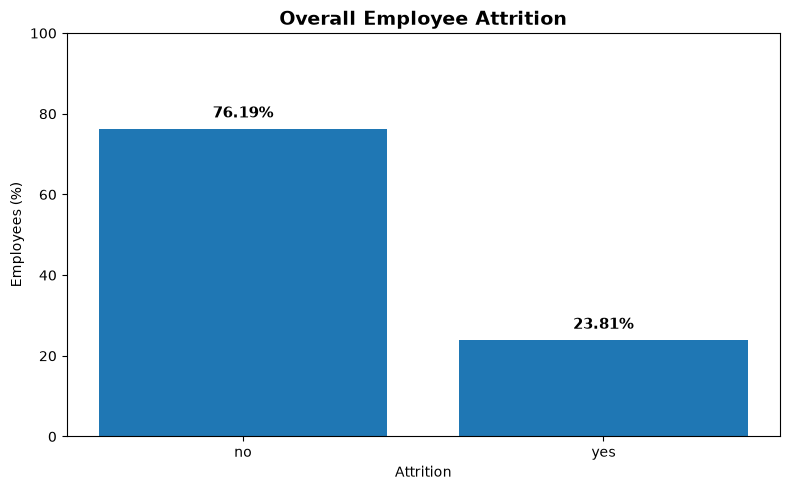

In [4]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    attrition_summary["Attrition"],
    attrition_summary["Percentage"]
)

plt.title(
    "Overall Employee Attrition",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Attrition")
plt.ylabel("Employees (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, attrition_summary["Percentage"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Interpretation

The dataset contains 14,999 employees, of whom 3,571 (23.81%) are recorded as having left the company.

This establishes an overall historical attrition rate of 23.81% for the dataset. Subsequent analysis will examine whether this rate differs across employee characteristics and groups.

This is a descriptive baseline and does not imply that any particular employee characteristic caused attrition.

## 2. Attrition by Department

This section examines whether observed attrition rates differ across departments.

Because departments vary substantially in size, attrition rate is calculated within each department rather than comparing only the number of employees who left.

In [6]:
department_attrition = (
    pd.crosstab(
        df_analysis["dept"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

department_attrition = department_attrition.sort_values(
    "yes",
    ascending=False
)

display(department_attrition)

Attrition,no,yes
dept,,
hr,70.91,29.09
accounting,73.40,26.60
technical,74.38,25.62
support,75.10,24.90
sales,75.51,24.49
marketing,76.34,23.66
IT,77.75,22.25
product_mng,78.05,21.95
RandD,84.63,15.37


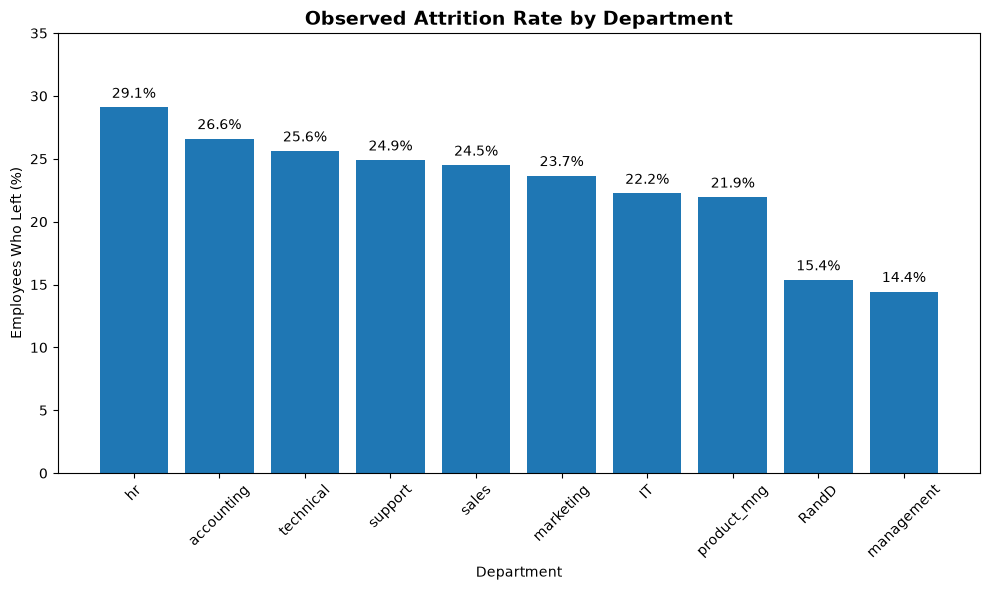

In [7]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    department_attrition.index,
    department_attrition["yes"]
)

plt.title(
    "Observed Attrition Rate by Department",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Department")
plt.ylabel("Employees Who Left (%)")
plt.xticks(rotation=45)
plt.ylim(0, 35)

for bar, value in zip(
    bars,
    department_attrition["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Interpretation

Observed attrition rates differ across departments.

HR has the highest observed attrition rate at approximately 29.1%, followed by Accounting at 26.6% and Technical at 25.6%. Management and R&D have the lowest observed rates at approximately 14.4% and 15.4%, respectively.

These differences indicate an association between department and attrition in this historical dataset. They should not be interpreted as evidence that department membership itself causes employees to leave.

Department size should also be considered when interpreting these percentages, since smaller departments can produce less stable estimates.

### Interpretation

Observed attrition rates differ across departments.

HR has the highest observed attrition rate at approximately 29.1%, followed by Accounting at 26.6% and Technical at 25.6%. Management and R&D have the lowest observed rates at approximately 14.4% and 15.4%, respectively.

These differences indicate an association between department and attrition in this historical dataset. They should not be interpreted as evidence that department membership itself causes employees to leave.

Department size should also be considered when interpreting these percentages, since smaller departments can produce less stable estimates.

In [8]:
salary_attrition = (
    pd.crosstab(
        df_analysis["salary"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

salary_attrition = salary_attrition.sort_values(
    "yes",
    ascending=False
)

display(salary_attrition)

Attrition,no,yes
salary,,
low,70.31,29.69
medium,79.57,20.43
high,93.37,6.63


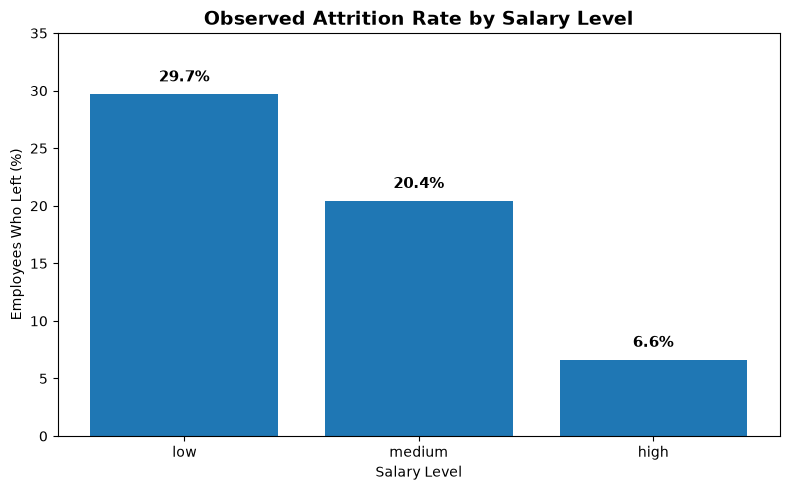

In [9]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    salary_attrition.index,
    salary_attrition["yes"]
)

plt.title(
    "Observed Attrition Rate by Salary Level",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Salary Level")
plt.ylabel("Employees Who Left (%)")
plt.ylim(0, 35)

for bar, value in zip(
    bars,
    salary_attrition["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Interpretation

Observed attrition varies substantially across salary levels.

The low-salary group has an observed attrition rate of approximately 29.7%, compared with 20.4% for medium salary and 6.6% for high salary.

This indicates a clear association between salary category and attrition in the historical dataset. However, the analysis does not establish that salary level itself caused employees to leave, since other employee characteristics may also differ across these groups.

Salary will therefore be examined alongside other variables in the statistical and predictive analysis.

## 4. Satisfaction Level and Attrition

Employee satisfaction is examined by comparing its distribution between employees who stayed and employees who left.

The analysis uses group-level summary statistics and a boxplot to show differences in the central tendency and spread of satisfaction scores.

In [10]:
satisfaction_summary = (
    df_analysis
    .groupby("Attrition")["satisfaction_level"]
    .agg(
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
    .round(3)
)

display(satisfaction_summary)

,Mean,Median,Minimum,Maximum
Attrition,,,,
no,0.667,0.69,0.12,1.00
yes,0.440,0.41,0.09,0.92


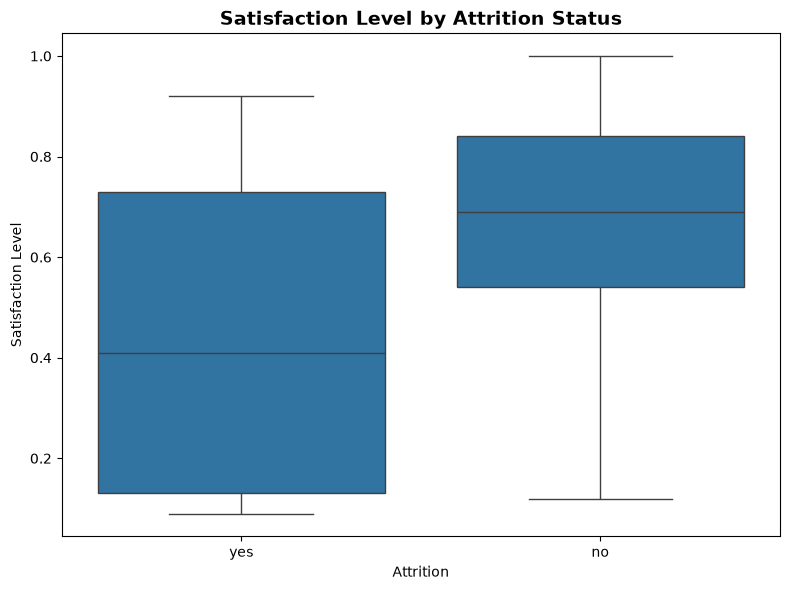

In [11]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="satisfaction_level"
)

plt.title(
    "Satisfaction Level by Attrition Status",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Attrition")
plt.ylabel("Satisfaction Level")

plt.tight_layout()
plt.show()

### Interpretation

Employees who left had substantially lower satisfaction scores than employees who stayed.

The median satisfaction level was 0.41 among employees who left compared with 0.69 among employees who stayed. The corresponding mean values were 0.440 and 0.667.

This is one of the clearest descriptive differences observed so far. The result indicates a strong association between satisfaction level and attrition in this dataset, but it does not establish that lower satisfaction caused employees to leave.

Satisfaction level will therefore be examined further in the statistical and predictive analysis.

## 5. Work Characteristics by Attrition

This section compares work-related characteristics between employees who stayed and employees who left.

The variables examined are:

- Last evaluation score
- Number of projects
- Average monthly hours
- Time spent at the company

Group means and medians are reported because some variables show non-linear relationships with attrition, meaning that averages alone may not fully describe the observed pattern.

In [13]:
work_characteristics_summary = (
    df_analysis
    .groupby("Attrition")[
        [
            "last_evaluation",
            "number_project",
            "average_montly_hours",
            "time_spend_company"
        ]
    ]
    .agg(["mean", "median"])
    .round(2)
)

display(work_characteristics_summary)

last_evaluation        number_project        average_montly_hours  \
                     mean median           mean median                 mean   
Attrition                                                                     
no                   0.72   0.71           3.79    4.0               199.06   
yes                  0.72   0.79           3.86    4.0               207.42   

                 time_spend_company         
          median               mean median  
Attrition                                   
no         198.0               3.38    3.0  
yes        224.0               3.88    4.0

### Interpretation

The average evaluation score is almost identical between employees who stayed and those who left (0.72 in both groups), although the median evaluation score is higher among employees who left (0.79 versus 0.71).

The average number of projects is also similar between the two groups, while monthly working hours and tenure show more noticeable differences.

Employees who left had a higher median monthly workload (224 hours versus 198 hours) and higher median tenure (4 years versus 3 years).

These results suggest that attrition patterns may not be adequately described by simple linear relationships. Project count, monthly hours, and tenure will therefore be examined by individual levels or ranges in the next section.

## 6. Attrition Across Monthly Workload Bands

Average monthly hours showed a noticeable difference between employees who stayed and those who left.

To investigate this further, monthly hours are divided into workload bands. This allows us to identify whether attrition varies across different levels of reported monthly working hours rather than assuming a simple linear relationship.

In [14]:
df_analysis["monthly_hours_band"] = pd.cut(
    df_analysis["average_montly_hours"],
    bins=[0, 160, 200, 240, 280, np.inf],
    labels=[
        "≤160",
        "161–200",
        "201–240",
        "241–280",
        "281+"
    ]
)

monthly_hours_attrition = (
    pd.crosstab(
        df_analysis["monthly_hours_band"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

monthly_hours_attrition = monthly_hours_attrition.sort_index()

display(monthly_hours_attrition)

Attrition,no,yes
monthly_hours_band,,
≤160,63.73,36.27
161–200,97.42,2.58
201–240,87.94,12.06
241–280,70.71,29.29
281+,19.40,80.60


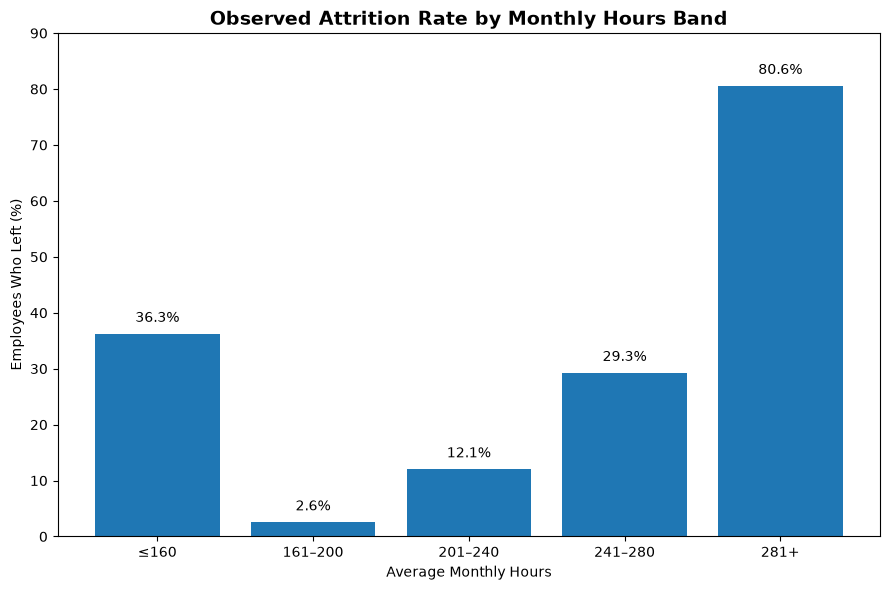

In [15]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    monthly_hours_attrition.index.astype(str),
    monthly_hours_attrition["yes"]
)

plt.title(
    "Observed Attrition Rate by Monthly Hours Band",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average Monthly Hours")
plt.ylabel("Employees Who Left (%)")
plt.ylim(0, 90)

for bar, value in zip(
    bars,
    monthly_hours_attrition["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Interpretation

Observed attrition varies substantially across monthly workload bands and does not follow a simple linear pattern.

The 161–200 hour group has the lowest observed attrition rate at approximately 2.6%. Attrition is higher among employees reporting 241–280 hours (29.3%) and is particularly high in the 281+ hour group (80.6%).

The ≤160-hour group also shows elevated observed attrition at 36.3%.

These patterns indicate that both relatively low and especially high reported monthly hours are associated with higher observed attrition in this dataset. The results should not be interpreted as evidence that working hours caused employees to leave, since other employee characteristics may also differ across these groups.

The 281+ group contains 562 employees, so its high observed rate should also be interpreted alongside its group size.

## 7. Attrition by Number of Projects

This section examines how observed attrition varies with the number of projects assigned to employees.

Rather than assuming a linear relationship, attrition is calculated separately for each project count.

In [16]:
project_attrition = (
    pd.crosstab(
        df_analysis["number_project"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

project_attrition = project_attrition.sort_index()

display(project_attrition)

Attrition,no,yes
number_project,,
2,34.38,65.62
3,98.22,1.78
4,90.63,9.37
5,77.83,22.17
6,44.21,55.79
7,0.00,100.00


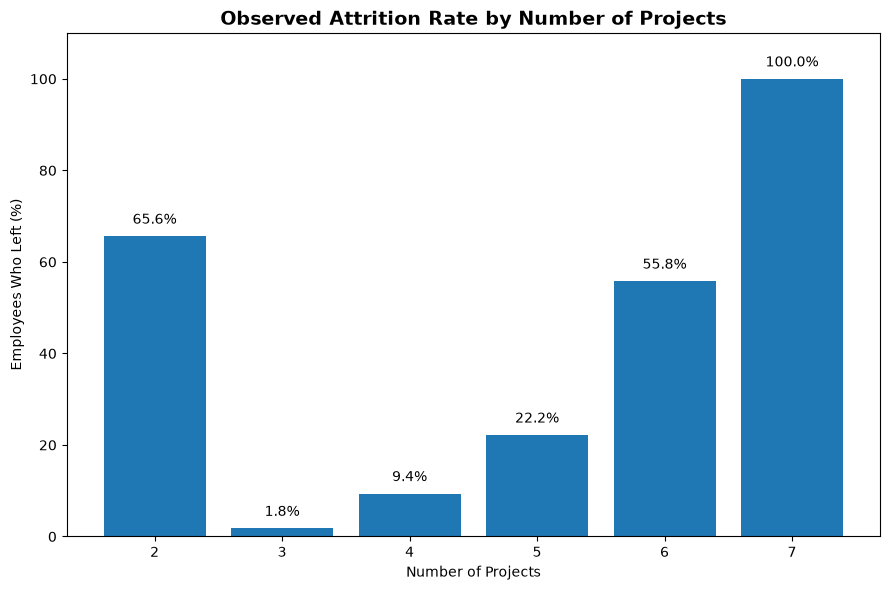

In [17]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    project_attrition.index.astype(str),
    project_attrition["yes"]
)

plt.title(
    "Observed Attrition Rate by Number of Projects",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Projects")
plt.ylabel("Employees Who Left (%)")
plt.ylim(0, 110)

for bar, value in zip(
    bars,
    project_attrition["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Interpretation

Observed attrition varies substantially by project count and shows a clearly non-linear pattern.

Employees with 3 projects have the lowest observed attrition rate at approximately 1.8%. Attrition is higher among employees with 2 projects (65.6%), 6 projects (55.8%), and 7 projects (100%).

The 7-project group requires particular caution because the observed 100% attrition rate does not mean that seven projects universally results in attrition. The group contains only 256 employees, and the analysis is based on this historical dataset.

Overall, the results indicate that project count is strongly associated with observed attrition, with both relatively low and high project counts showing elevated rates compared with the middle of the distribution.

## 8. Attrition by Years at the Company

This section examines observed attrition across employee tenure levels.

The purpose is to determine whether attrition varies consistently with tenure or whether particular tenure groups show distinct patterns.

In [18]:
tenure_attrition = (
    pd.crosstab(
        df_analysis["time_spend_company"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

tenure_attrition = tenure_attrition.sort_index()

display(tenure_attrition)

Attrition,no,yes
time_spend_company,,
2,98.37,1.63
3,75.38,24.62
4,65.19,34.81
5,43.45,56.55
6,70.89,29.11
7,100.00,0.00
8,100.00,0.00
10,100.00,0.00


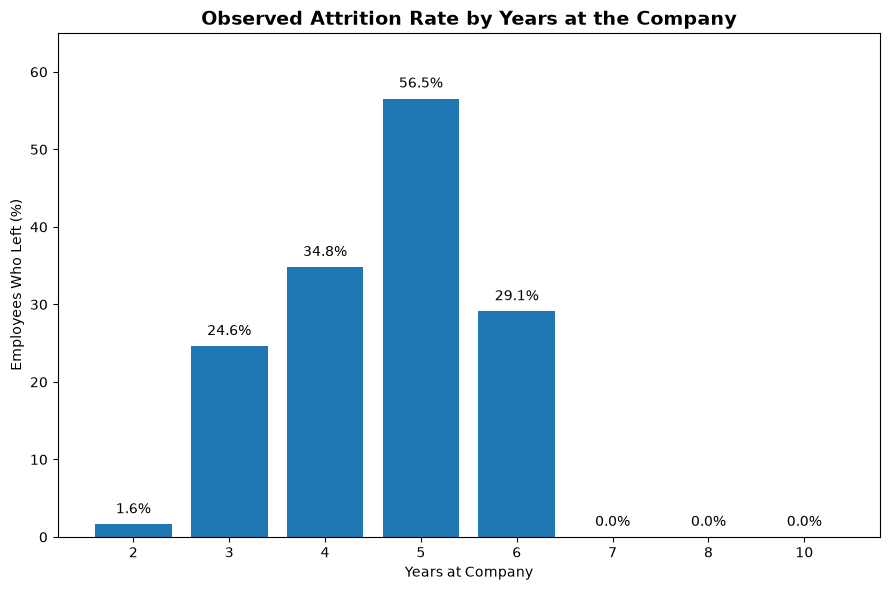

In [19]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    tenure_attrition.index.astype(str),
    tenure_attrition["yes"]
)

plt.title(
    "Observed Attrition Rate by Years at the Company",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Years at Company")
plt.ylabel("Employees Who Left (%)")
plt.ylim(0, 65)

for bar, value in zip(
    bars,
    tenure_attrition["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Interpretation

Observed attrition varies substantially across tenure levels and does not increase monotonically with years at the company.

Attrition is relatively low among employees with 2 years of tenure (1.6%), increases at 3 and 4 years, and reaches 56.6% among employees with 5 years of tenure.

The observed rate then falls to 29.1% at 6 years and reaches 0% in the 7-, 8-, and 10-year groups.

The zero observed attrition in the longest-tenure groups should be interpreted cautiously because these groups are relatively small compared with the 3- and 4-year groups.

Overall, tenure shows a non-linear association with attrition rather than a simple pattern in which risk continuously increases with time at the company.

## 9. Statistical Association — Categorical Variables

Visual differences in attrition rates do not by themselves establish whether the observed differences are statistically meaningful.

The Chi-square test of independence is used to test whether attrition status is statistically associated with each categorical variable.

### Hypotheses

- **H₀:** The variable and attrition are independent.
- **H₁:** The variable and attrition are associated.

A p-value below 0.05 is treated as evidence against the null hypothesis.

Statistical significance does not establish causation and does not indicate the practical importance of an association. Effect sizes will therefore be examined separately.

In [22]:
categorical_variables = [
    "dept",
    "salary",
    "Work_accident",
    "promotion_last_5years"
]

chi_square_results = []

for variable in categorical_variables:
    contingency_table = pd.crosstab(
        df_analysis[variable],
        df_analysis["Attrition"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_square_results.append({
        "Variable": variable,
        "Chi_Square": chi2,
        "p_value": p_value,
        "Degrees_of_Freedom": dof
    })

chi_square_results = pd.DataFrame(
    chi_square_results
)

chi_square_results["Significant_at_0.05"] = (
    chi_square_results["p_value"] < 0.05
)

chi_square_results["Chi_Square"] = (
    chi_square_results["Chi_Square"].round(3)
)

chi_square_results["p_value"] = (
    chi_square_results["p_value"].map(
        lambda x: f"{x:.2e}"
    )
)

display(chi_square_results)

,Variable,Chi_Square,p_value,Degrees_of_Freedom,Significant_at_0.05
0,dept,86.825,7.04e-15,9,True
1,salary,381.225,1.65e-83,2,True
2,Work_accident,357.562,9.56e-80,1,True
3,promotion_last_5years,56.262,6.34e-14,1,True


### Interpretation

All four categorical variables tested show statistically significant associations with attrition at the 5% significance level.

Salary and Work_accident have substantially larger Chi-square statistics than department and promotion status, although the Chi-square statistic itself should not be used to compare association strength across variables with different numbers of categories.

These results provide statistical evidence that the distribution of attrition differs across the categories of each variable.

However, statistical significance alone does not indicate the magnitude or practical importance of an association. Effect sizes will therefore be calculated next.

## 10. Effect Size — Cramér's V

Statistical significance does not tell us how large an association is.

Cramér's V is calculated to quantify the strength of association between each categorical variable and attrition.

The statistic ranges from 0 to 1, where values closer to 0 indicate weaker association and values closer to 1 indicate stronger association.

The results are interpreted as measures of association, not causal effects.

In [23]:
def cramers_v(data, variable, target="Attrition"):
    contingency_table = pd.crosstab(
        data[variable],
        data[target]
    )

    chi2, _, _, _ = chi2_contingency(
        contingency_table
    )

    n = contingency_table.sum().sum()
    rows, columns = contingency_table.shape

    phi2 = chi2 / n

    correction = (
        (columns - 1) * (rows - 1)
    ) / (n - 1)

    phi2_corrected = max(
        0,
        phi2 - correction
    )

    rows_corrected = (
        rows
        - ((rows - 1) ** 2) / (n - 1)
    )

    columns_corrected = (
        columns
        - ((columns - 1) ** 2) / (n - 1)
    )

    denominator = min(
        columns_corrected - 1,
        rows_corrected - 1
    )

    return np.sqrt(
        phi2_corrected / denominator
    )


effect_size_results = []

for variable in categorical_variables:
    effect_size_results.append({
        "Variable": variable,
        "Cramers_V": cramers_v(
            df_analysis,
            variable
        )
    })

effect_size_results = (
    pd.DataFrame(effect_size_results)
    .sort_values(
        "Cramers_V",
        ascending=False
    )
    .reset_index(drop=True)
)

effect_size_results["Cramers_V"] = (
    effect_size_results["Cramers_V"].round(4)
)

display(effect_size_results)

,Variable,Cramers_V
0,salary,0.1590
1,Work_accident,0.1542
2,dept,0.0720
3,promotion_last_5years,0.0607


### Interpretation

Salary and Work_accident show the largest Cramér's V values among the categorical variables tested, while department and promotion_last_5years have smaller association measures.

This demonstrates why statistical significance and effect size should be considered together. With nearly 15,000 observations, even relatively small associations can produce very small p-values.

The effect sizes therefore provide additional context about the magnitude of the observed categorical associations.

These measures describe association in the historical dataset and should not be interpreted as causal effects.

## 11. Statistical Association — Numeric Variables

The previous section examined categorical variables using Chi-square tests and Cramér's V.

This section examines whether the distributions of numeric employee characteristics differ between employees who stayed and employees who left.

The Mann–Whitney U test is used because it does not require the two groups to follow a normal distribution.

### Hypotheses

- **H₀:** The distributions of the two groups are the same.
- **H₁:** The distributions of the two groups differ.

A p-value below 0.05 is treated as evidence against the null hypothesis.

Statistical significance indicates that the distributions differ; it does not establish that a variable caused an employee to leave.

In [24]:
numeric_variables = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company"
]

mann_whitney_results = []

for variable in numeric_variables:
    
    stayed = df_analysis.loc[
        df_analysis["Attrition"] == "no",
        variable
    ]
    
    left = df_analysis.loc[
        df_analysis["Attrition"] == "yes",
        variable
    ]
    
    u_statistic, p_value = mannwhitneyu(
        stayed,
        left,
        alternative="two-sided"
    )
    
    mann_whitney_results.append({
        "Variable": variable,
        "Stayed_Median": stayed.median(),
        "Left_Median": left.median(),
        "U_Statistic": u_statistic,
        "p_value": p_value
    })

mann_whitney_results = pd.DataFrame(
    mann_whitney_results
)

mann_whitney_results["Stayed_Median"] = (
    mann_whitney_results["Stayed_Median"].round(3)
)

mann_whitney_results["Left_Median"] = (
    mann_whitney_results["Left_Median"].round(3)
)

mann_whitney_results["U_Statistic"] = (
    mann_whitney_results["U_Statistic"].round(1)
)

mann_whitney_results["p_value"] = (
    mann_whitney_results["p_value"].map(
        lambda x: f"{x:.2e}"
    )
)

display(mann_whitney_results)

,Variable,Stayed_Median,Left_Median,U_Statistic,p_value
0,satisfaction_level,0.69,0.41,30522915.0,0.00e+00
1,last_evaluation,0.71,0.79,20472187.0,7.65e-01
2,number_project,4.00,4.00,20930147.0,1.67e-02
3,average_montly_hours,198.00,224.00,19119787.5,1.28e-08
4,time_spend_company,3.00,4.00,13331224.0,8.66e-238


In [26]:
# Recalculate significance directly from the original p-values

mann_whitney_results["Significant_at_0.05"] = [
    float(p) < 0.05
    for p in [
        mannwhitneyu(
            df_analysis.loc[
                df_analysis["Attrition"] == "no",
                variable
            ],
            df_analysis.loc[
                df_analysis["Attrition"] == "yes",
                variable
            ],
            alternative="two-sided"
        )[1]
        for variable in numeric_variables
    ]
]

display(mann_whitney_results)

,Variable,Stayed_Median,Left_Median,U_Statistic,p_value,Significant_at_0.05
0,satisfaction_level,0.69,0.41,30522915.0,0.00e+00,True
1,last_evaluation,0.71,0.79,20472187.0,7.65e-01,False
2,number_project,4.00,4.00,20930147.0,1.67e-02,True
3,average_montly_hours,198.00,224.00,19119787.5,1.28e-08,True
4,time_spend_company,3.00,4.00,13331224.0,8.66e-238,True


## 12. Key Findings from Exploratory & Statistical Analysis

The analysis identified several notable patterns and statistical associations in the historical employee dataset.

### 1. Overall attrition

The historical attrition rate was **23.81%**, with 3,571 of 14,999 employees recorded as having left.

### 2. Satisfaction

Employees who left had substantially lower satisfaction scores than employees who stayed.

- Stayed: median satisfaction = **0.69**
- Left: median satisfaction = **0.41**

The difference was statistically significant.

### 3. Workload

Monthly working hours differed significantly between the two groups.

- Stayed: median = **198 hours**
- Left: median = **224 hours**

The workload analysis also showed a non-linear pattern, with particularly high observed attrition among employees reporting very high monthly hours.

### 4. Projects and tenure

The number of projects showed a statistically significant distributional difference between employees who stayed and those who left.

Tenure also differed significantly between the groups, with employees who left having a median tenure of four years compared with three years among employees who stayed.

Both variables showed non-linear patterns across their individual levels.

### 5. Categorical variables

Salary, work-accident status, department, and promotion history all showed statistically significant associations with attrition.

Cramér's V indicated that **salary and work-accident status had the largest categorical association measures among the variables tested**, while department and promotion history had smaller association measures.

### 6. Evaluation score

Last evaluation showed no statistically significant difference between employees who stayed and those who left under the Mann–Whitney U test (p ≈ 0.765).

This is an important reminder that variables should not be judged solely from visual patterns or descriptive differences.

### 7. Overall analytical conclusion

The strongest observed patterns in this dataset involve employee satisfaction, workload, tenure, project assignment, and selected categorical characteristics.

These findings identify variables and employee groups that warrant further investigation and provide a foundation for predictive modeling.

The analysis describes historical associations and does not establish that any individual factor caused an employee to leave.

## 13. Transition to Predictive Modeling

The exploratory and statistical analysis provides a basis for developing an employee attrition prediction model.

The next notebook will use the identified employee characteristics as model features and evaluate whether historical employee data can distinguish employees with different levels of predicted attrition risk.

The modeling workflow will include:

- Logistic Regression as an interpretable baseline
- Random Forest as a non-linear model
- Stratified train/test splitting
- Multiple classification metrics
- ROC-AUC and PR-AUC
- Confusion matrices
- Feature interpretation
- Permutation importance
- Probability and risk-band analysis

Model performance will be evaluated on held-out data, and predicted risk will be interpreted as model output rather than certainty or causation.